# Rewind the Sky — S250206dm: a neutron-star merger alert under a bright Moon

**Question.** A *high-significance* LVK alert likely containing a neutron star (NSBH 55 %, BNS 37 %) arrives at night in La Palma.
The localisation starts at ~2100 deg² and shrinks to 547 deg² over 38 hours. A neutrino track and, a day later, a fast radio burst are
reported as possible counterparts. The Moon is 67 % illuminated. *With only what was known at each moment, what could an IACT have done?*

There is **no real IACT history** to compare with: none of the 62 GCN circulars mentions MAGIC, LST, H.E.S.S., VERITAS or CTAO.
This case study therefore asks a narrower question than S241125n: how much do **the Moon** and **the improving localisation** decide
what is possible? Everything runs offline from `data/`; see **Known limitations** at the end.

In [1]:
import sys, json, re, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import healpy as hp
from rewindsky.replay import load_log, state_at, t_after, parse_t, format_snapshot
from rewindsky import plots, plots_study as ps, study, skymaps as sm, s250206dm as E
from rewindsky.quiz import Quiz

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 100
FIG = Path("figures/s250206dm"); FIG.mkdir(parents=True, exist_ok=True)
log = load_log(E.EVENT)
H = lambda t: (pd.Timestamp(t) - pd.Timestamp(E.T0)).total_seconds() / 3600
alerts = [r for r in log["rows"] if r["kind"] == "gw_alert"]
print(f"{log['event']}: t0 = {log['t0']} UTC;", pd.Series([r["kind"] for r in log["rows"]]).value_counts().to_dict())

S250206dm: t0 = 2025-02-06T21:25:30 UTC; {'gcn_circular': 62, 'gw_alert': 7, 'gracedb_map': 5}


## 1. Data and independent checks

Same rules as S241125n: LVK alert time = notice distribution time (GraceDB VOEvent), circular time = NASA `createdOn` rounded up to the next second,
sky maps from GraceDB rasterised to nside 512, Astro-COLIBRI used only as a cross-check.

In [2]:
def quoted(n):
    body = json.loads(Path(f"data/gcn/S250206dm/{n}.json").read_text())["body"]
    return [float(x) for x in re.findall(r"credible region is ([\d.]+) deg2", body)]
mine = {r["label"]: r["data"]["area90"] for r in alerts}
rows = [("90% area vs LVK circular", f"{lab} vs GCN {n}", f"{mine[lab]:.1f}", f"{quoted(n)[0]:g}")
        for lab, n in [("Initial #3", 39175), ("Update #4", 39178), ("Update #6", 39184), ("Update #7", 39231)]]
for r in alerts:
    raw = json.loads(Path(f"data/raw/event__gw_S250206dm_{r['revision'].split('_')[1]}.json").read_text())["body"]
    rows.append(("90% area vs Astro-COLIBRI", r["label"], f"{r['data']['area90']:.1f}", json.loads(raw["map_areas"])["90"]))
lag = [(parse_t(r["platform_time"]) - parse_t(r["t"])).total_seconds() for r in alerts]
rows.append(("platform lag behind the notice", "7 notices", f"{min(lag):.0f}-{max(lag):.0f} s", "small, positive"))
pd.DataFrame(rows, columns=["check", "item", "ours", "reference"])

,check,item,ours,reference
0,90% area vs LVK circular,Initial #3 vs GCN 39175,1543.7,1544
1,90% area vs LVK circular,Update #4 vs GCN 39178,1625.7,1626
2,90% area vs LVK circular,Update #6 vs GCN 39184,909.9,910
3,90% area vs LVK circular,Update #7 vs GCN 39231,547.0,547
4,90% area vs Astro-COLIBRI,Preliminary #1,2138.9,2139
5,90% area vs Astro-COLIBRI,Preliminary #2,1543.7,1544
6,90% area vs Astro-COLIBRI,Initial #3,1543.7,1544
7,90% area vs Astro-COLIBRI,Update #4,1625.7,1626
8,90% area vs Astro-COLIBRI,Update #5,1625.7,1626
9,90% area vs Astro-COLIBRI,Update #6,909.9,910


## 2. Replay: what was known when

In [3]:
for kw in (dict(seconds=40), dict(minutes=6), dict(hours=1.3), dict(hours=5.5), dict(hours=38)):
    print(format_snapshot(state_at(log, t_after(log, **kw)))); print()

=== S250206dm @ 2025-02-06T21:26:10  (T0 + 0.01 h) ===
Latest LVK alert: Preliminary #1 (available 2025-02-06T21:26:02)  [SIGNIFICANT alert]
  localisation: 50%=715.6 deg2  90%=2138.9 deg2  lobes(90%): (157,-33), (6,+35)
  peak-probability pixel (not the localisation!): RA=341.7 Dec=+8.2
  distance ~430 Mpc  FAR=0.819 per year
  class: Terrestrial=73% BNS=22% NSBH=5% BBH=0%;  P(has NS | astrophysical)=1.0
  comment: (none)
Alerts so far: 1 -> Preliminary #1
GCN circulars so far: 0  {}

=== S250206dm @ 2025-02-06T21:31:30  (T0 + 0.10 h) ===
Latest LVK alert: Preliminary #2 (available 2025-02-06T21:30:52)  [SIGNIFICANT alert]
  localisation: 50%=486.0 deg2  90%=1543.7 deg2  lobes(90%): (160,-36), (3,+33)
  peak-probability pixel (not the localisation!): RA=2.8 Dec=+34.7
  distance ~409 Mpc  FAR=0.04 per year
  class: Terrestrial=8% BNS=37% NSBH=55% BBH=0%;  P(has NS | astrophysical)=1.0
  comment: (none)
Alerts so far: 2 -> Preliminary #1, Preliminary #2
GCN circulars so far: 0  {}

=== 

The first alert came from MBTA with a **72.5 % terrestrial** probability; 4.8 minutes later PyCBC made it a confident NSBH/BNS candidate
(terrestrial 7.7 %). The classification then never changed; only the localisation did.

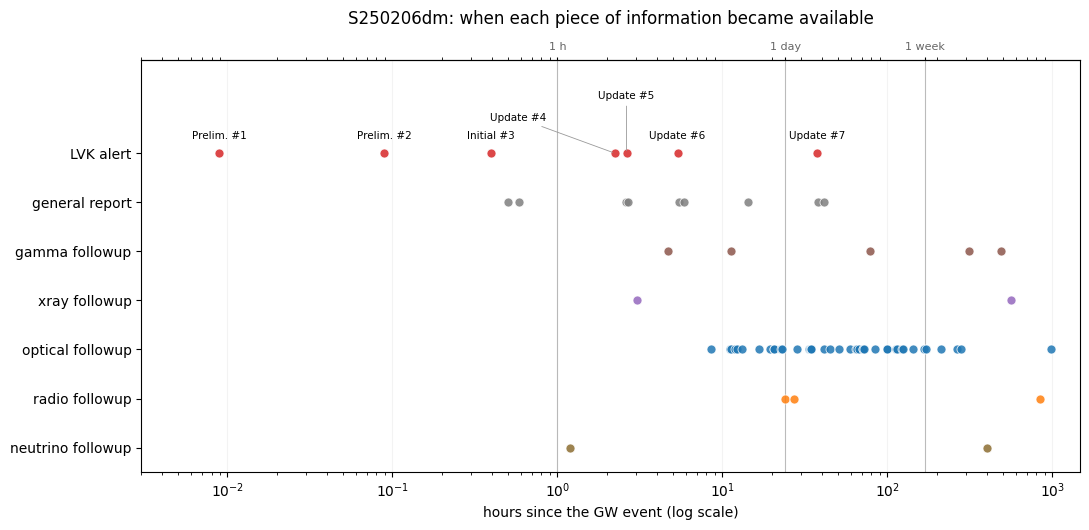

In [4]:
fig, ax = plt.subplots(figsize=(11, 5.4)); plots.timeline(log, ax=ax); fig.tight_layout(); fig.savefig(FIG / "01_timeline.png", dpi=130); plt.show()

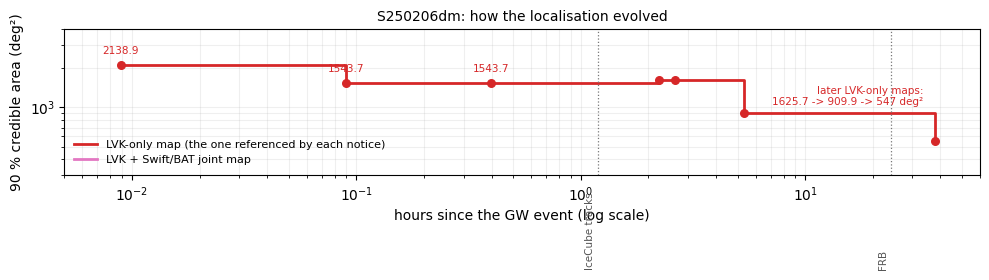

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.9))
ps.localisation_evolution(log, ax=ax, notes=[(H("2025-02-06 22:36:52"), "IceCube tracks"), (H("2025-02-07 21:26:31"), "FRB")])
ax.set_ylim(300, 4000)
fig.tight_layout(); fig.savefig(FIG / "02_localisation.png", dpi=130); plt.show()

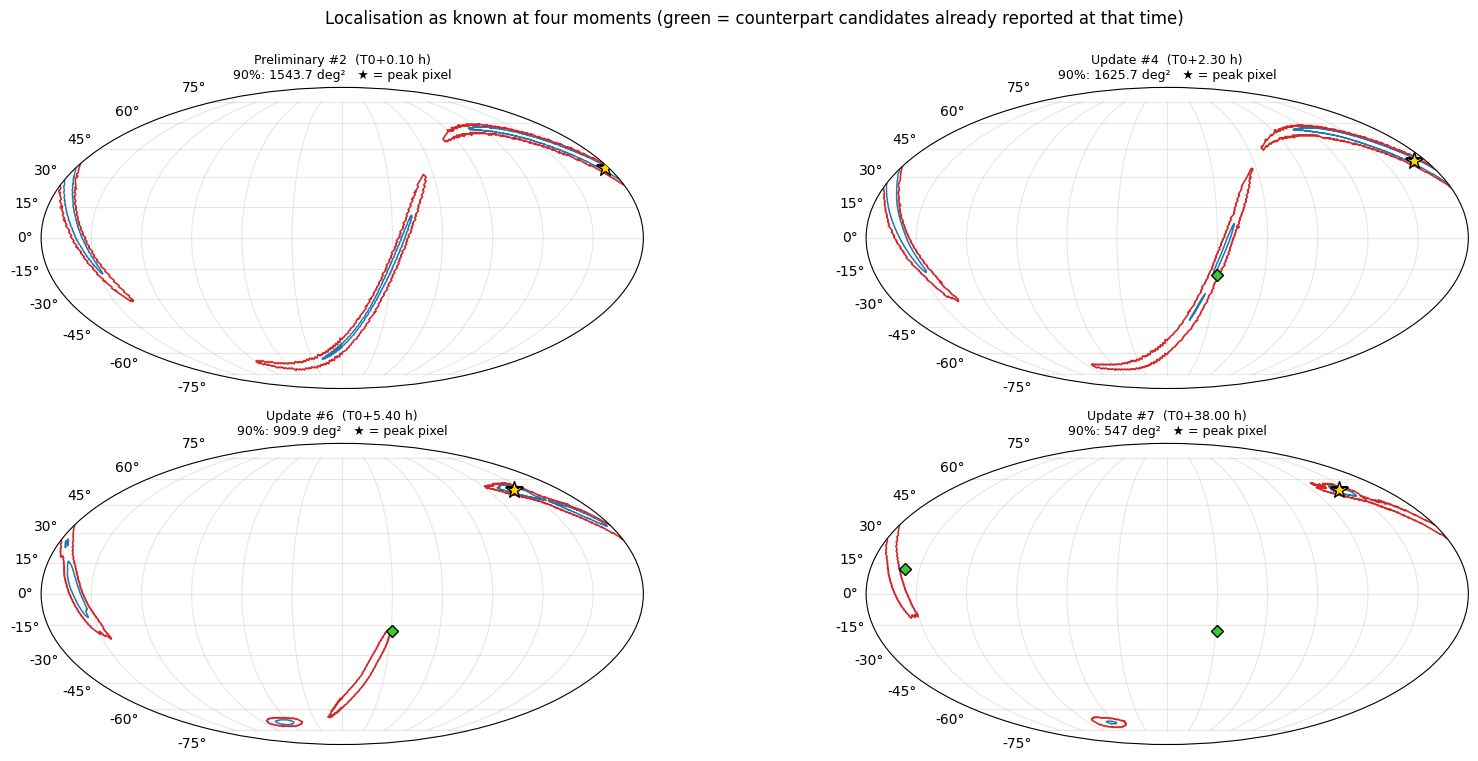

In [6]:
fig = plt.figure(figsize=(17, 7.6))
marks = [(E.ICECUBE[0], E.ICECUBE[1], "IceCube track 1"), (E.FRB[0], E.FRB[1], "FRB 20250206A")]
for i, h in enumerate([0.1, 2.3, 5.4, 38]):
    ax = fig.add_subplot(2, 2, i + 1, projection="mollweide")
    known = [m for m, t in zip(marks, ["2025-02-06 22:36:52", "2025-02-07 21:26:31"]) if H(t) <= h]
    plots.skymap(log, t_after(log, hours=h), ax=ax, marks=known)
fig.suptitle("Localisation as known at four moments (green = counterpart candidates already reported at that time)", y=.995)
fig.tight_layout(); fig.savefig(FIG / "03_skymaps.png", dpi=110, bbox_inches="tight"); plt.show()

## 3. The candidates, as the maps saw them then and later

The *credible level* of a position is the smallest credible region that contains it (0 = the peak; 0.9 = on the 90 % contour; 1 = outside
everything). Each column is a map, in the order it was released.

In [7]:
maps = [("bayestar_0", "#1, T+0.01 h"), ("bayestar_1", "#2-#3, T+0.09 h"), ("bilby_0", "#4, T+2.2 h"), ("bilby_1", "#6, T+5.3 h"), ("bilby_offline1_0", "#7, T+37.7 h")]
lev = {}
for key, lab in maps:
    p, ns = sm.load_flat(study.ROOT / E.SK / f"{key}.fits.gz")
    order = np.argsort(p)[::-1]; cum = np.empty_like(p); cum[order] = np.cumsum(p[order])
    lev[lab] = {n: round(float(cum[hp.ang2pix(ns, *pos, nest=True, lonlat=True)]), 3) for n, pos in E.CANDIDATES.items()}
pd.DataFrame(lev)

,"#1, T+0.01 h","#2-#3, T+0.09 h","#4, T+2.2 h","#6, T+5.3 h","#7, T+37.7 h"
IceCube track 1,0.715,0.845,0.738,0.928,0.981
IceCube track 2,0.935,0.967,0.986,1.000,0.999
FRB 20250206A,0.972,0.992,0.994,1.000,1.000


IceCube computed its coincidence with the map of the *3-Initial* notice, where track 1 sits at the 85 % level, inside the 90 % region.
As the localisation improved, the same position slid to the 93 % level (T+5.3 h) and to **98 %** in the final map. Track 2 was never well
inside. The FRB lies outside the final map entirely (CHIME itself put it at the 99.96 % level), and it is **32° from the Sun**, so no
night-time telescope could have looked at it anyway. *A candidate that looked coincident when it was reported can become implausible
hours later; a replay shows that drift, a retrospective table does not.*

## 4. The Moon decides the night

Dark time = Sun below −18° and Moon below −0.5° (tilepy's convention for IACTs).

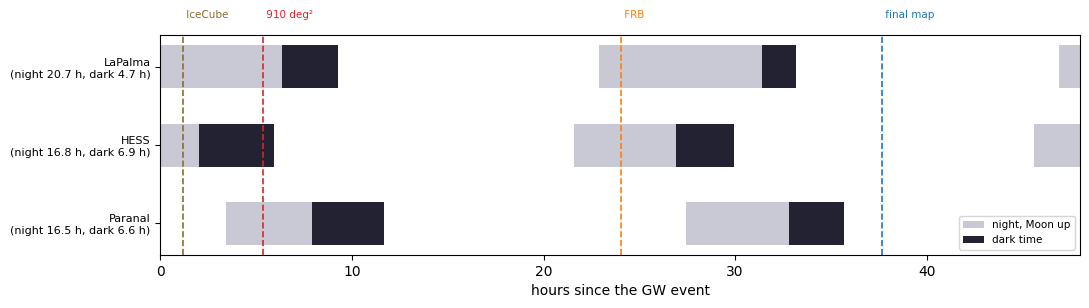

,LaPalma,HESS,Paranal
night (h),20.7,16.8,16.5
dark time (h),4.7,6.9,6.6


In [8]:
fig, ax = plt.subplots(figsize=(11, 3.2))
_, tot = ps.dark_windows(E.T0, ("LaPalma", "HESS", "Paranal"), hours=(0, 48), ax=ax,
                         marks=[(H("2025-02-06 22:36:52"), "IceCube", "#8c6d31"), (H("2025-02-07 02:46:08"), "910 deg²", "#d62728"),
                                (H("2025-02-07 21:26:31"), "FRB", "#ff7f0e"), (H("2025-02-08 11:06:27"), "final map", "#1f77b4")])
fig.tight_layout(); fig.savefig(FIG / "04_dark_time.png", dpi=120); plt.show()
pd.DataFrame(tot, index=["night (h)", "dark time (h)"]).round(1)

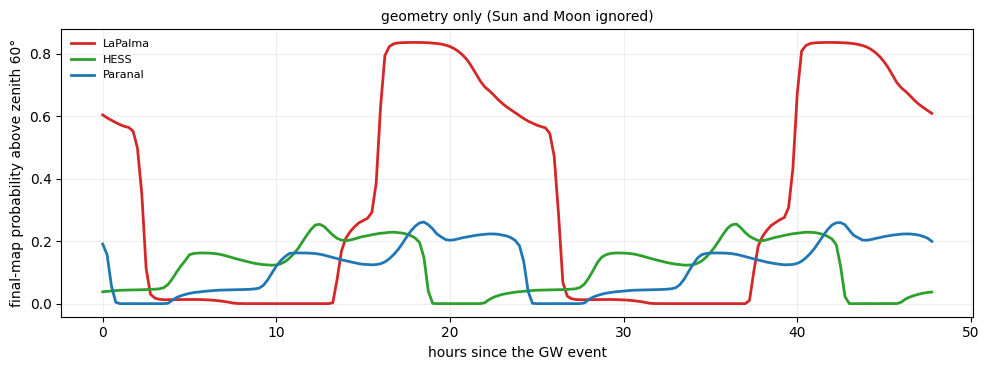

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for site, col in [("LaPalma", "#d62728"), ("HESS", "#2ca02c"), ("Paranal", "#1f77b4")]:
    h, v = ps.visible_probability(study.ROOT / E.SK / "bilby_offline1_0.fits.gz", site, E.T0, (0, 48), step_h=.25)
    ax.plot(h, v, color=col, lw=2, label=site)
ax.set_xlabel("hours since the GW event"); ax.set_ylabel("final-map probability above zenith 60°"); ax.grid(alpha=.2)
ax.legend(frameon=False, fontsize=8); ax.set_title("geometry only (Sun and Moon ignored)", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "05_visible_probability.png", dpi=120); plt.show()

La Palma is geometrically the best placed site (up to ~84 % of the final map above zenith 60°), but in the first 48 h it has only
~4.7 h of dark time, and the first dark window starts ~6.3 h after the event, when the Moon sets.

## 5. Six strategies

| | decisions (UTC) | information used |
|---|---|---|
| **A** act at once | 21:30:52, 23:39:39, 02:46:08, (+1 d) 11:06:27 | every LVK map from the first confident alert (#2) |
| **B** wait for PE | 23:39:39, 02:46:08, 11:06:27 | from the first Bilby map |
| **C** wait for < 1000 deg² | 02:46:08, 11:06:27 | from the 910 deg² map |
| **D** wait for the final map | (+1 d) 11:06:27 | the 547 deg² map only |
| **N** IceCube track | 22:36:53 (GCN 39176) | track 1 position (0.43° at 90 %) |
| **F** FRB | (+1 d) 21:26:32 (GCN 39216) | CHIME position |

Scoring: **Hfinal** = the final LVK map (the best estimate of where the source was); **Hearly** = the map known at T+5 min (to show how much the map moved).
Caveat: strategy D is scored on the very map it was planned on, which favours it; earlier strategies pay for the map's evolution.

In [10]:
res = study.run_study(E.EVENT, E.STRATEGIES, list(E.SENSITIVITY.values()), workers=4)
frames = {n: study.summarise(res, su.tag(), E.STRATEGIES, E.TRUTHS, su, E.T0) for n, su in E.SENSITIVITY.items()}
cols = ["n_tiles", "first_tile_h", "cov_Hfinal_first6", "cov_Hfinal_first12", "cov_Hfinal", "cov_Hearly_first12"]
for name in ("baseline (La Palma, dark time)", "moonlight mode (Moon <= 80 % lit)", "3 sites, moonlight mode"):
    print(f"--- {name}"); print(frames[name][cols].round(3).T.to_string()); print()

--- baseline (La Palma, dark time)
strategy                A      B      C    D      N    F
n_tiles             2.000  2.000  2.000  0.0  1.000  0.0
first_tile_h        6.310  6.310  6.310  NaN  6.310  NaN
cov_Hfinal_first6   0.005  0.005  0.005  0.0  0.001  0.0
cov_Hfinal_first12  0.005  0.005  0.005  0.0  0.001  0.0
cov_Hfinal          0.005  0.005  0.005  0.0  0.001  0.0
cov_Hearly_first12  0.022  0.022  0.022  0.0  0.007  0.0

--- moonlight mode (Moon <= 80 % lit)
strategy                 A       B       C    D      N    F
n_tiles             26.000  21.000  13.000  0.0  1.000  0.0
first_tile_h         0.090   2.240   5.340  NaN  2.190  NaN
cov_Hfinal_first6    0.486   0.434   0.515  0.0  0.001  0.0
cov_Hfinal_first12   0.498   0.443   0.568  0.0  0.001  0.0
cov_Hfinal           0.619   0.601   0.586  0.0  0.001  0.0
cov_Hearly_first12   0.205   0.155   0.174  0.0  0.007  0.0

--- 3 sites, moonlight mode
strategy                 A       B       C       D      N    F
n_tiles        

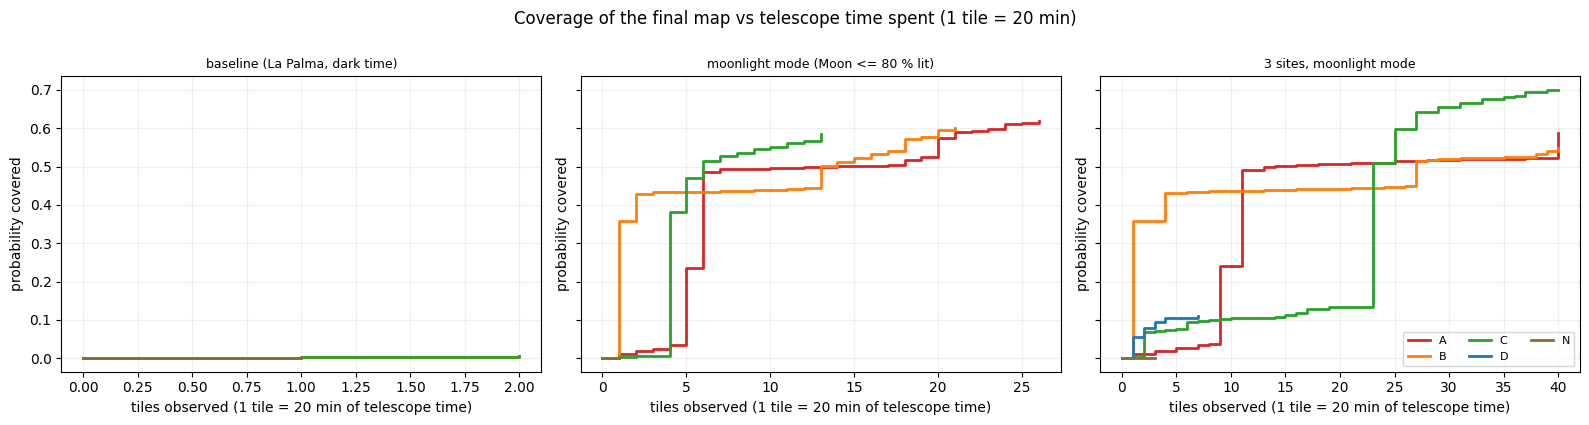

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, name in zip(axes, ("baseline (La Palma, dark time)", "moonlight mode (Moon <= 80 % lit)", "3 sites, moonlight mode")):
    su = E.SENSITIVITY[name]
    ps.coverage_vs_tiles(res, su.tag(), E.STRATEGIES, {"Hfinal": E.TRUTHS["Hfinal"]}, su, ax_pair=[ax], nmax=40)
    ax.set_title(name, fontsize=9)
axes[2].legend(ncol=3, fontsize=8, loc="lower right")   # labels come from each line (strategies without tiles have none)
fig.suptitle("Coverage of the final map vs telescope time spent (1 tile = 20 min)", y=1.0)
fig.tight_layout(); fig.savefig(FIG / "06_strategies.png", dpi=120); plt.show()

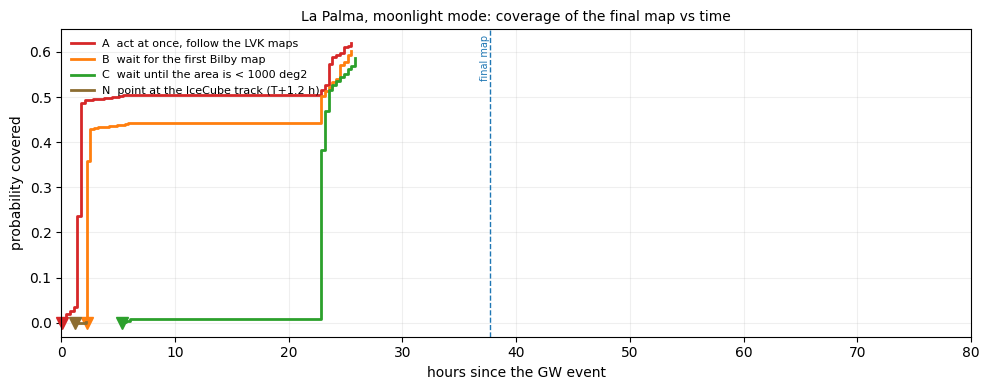

In [12]:
su = E.SENSITIVITY["moonlight mode (Moon <= 80 % lit)"]
fig, ax = plt.subplots(figsize=(10, 4))
ps.coverage_vs_time(res, su.tag(), E.STRATEGIES, {"Hfinal": E.TRUTHS["Hfinal"]}, su, E.T0, ax_pair=[ax], xlim=(0, 80),
                    marks=[(H("2025-02-08 11:06:27"), "final map", "#1f77b4")])
ax.legend(fontsize=8, frameon=False, loc="upper left"); ax.set_title("La Palma, moonlight mode: coverage of the final map vs time", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "07_coverage_time.png", dpi=120); plt.show()

**Three things in these numbers need explaining (all checked):**
1. *Dark time only gives 2 tiles.* When the Moon finally sets at La Palma (T+6.3 h), the part of the current map above zenith 60° is only 0.4–3 % and
   reaches 0 by T+8 h: the localisation has set too. The second night's dark window (≈1.8 h) has the same problem.
2. *D never observes at La Palma.* The final map arrives at T+37.7 h; the following nights have the Moon 85 %, 92 %, 97 % lit, above even the
   80 % moonlight limit. Waiting for the best map means missing every usable night.
3. *With three sites, the first 12 tiles can cover less.* Here "12 tiles" is telescope time summed over sites; C's first 12 tiles are 7 at Paranal,
   2 at H.E.S.S. and 3 at La Palma, and the southern sites see parts of the map with little final-map probability. Total coverage still rises (72 % vs 59 %).

## 6. Sensitivity

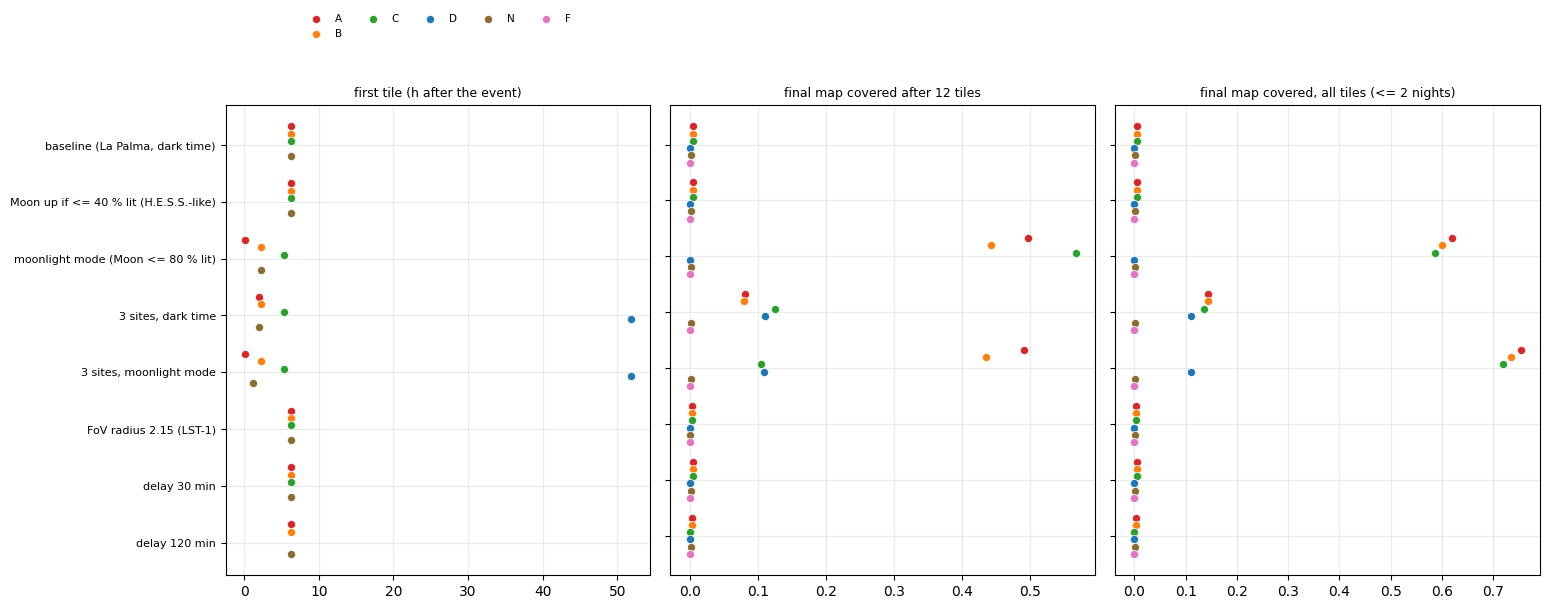

n_tiles                  first_tile_h                              cov_Hfinal_first12                                 cov_Hfinal                                
strategy                                     A   B   C  D  N  F            A     B     C      D     N   F                  A      B      C     D      N    F          A      B      C     D      N    F
setup                                                                                                                                                                                                  
baseline (La Palma, dark time)               2   2   2  0  1  0         6.31  6.31  6.31    NaN  6.31 NaN              0.005  0.005  0.005  0.00  0.001  0.0      0.005  0.005  0.005  0.00  0.001  0.0
Moon up if <= 40 % lit (H.E.S.S.-like)       2   2   2  0  1  0         6.26  6.26  6.26    NaN  6.26 NaN              0.005  0.005  0.005  0.00  0.001  0.0      0.005  0.005  0.005  0.00  0.001  0.0
moonlight mode (Moon <= 80 % lit)           26  21  13  0  1  0         0.09  2.24  5.34    NaN  2.19 NaN              0.498  0.443  0.568  0.00  0.001  0.0      0.619  0.601  0.586  0.00  0.001  0.0
3 sites, dark time                          37  37  28  8  3  0         1.92  2.24  5.34  51.86  1.92 NaN              0.081  0.080  0.125  0.11  0.001  0.0      0.143  0.143  0.136  0.11  0.001  0.0
3 sites, moonlight mode                     68  62  44  7  3  0         0.09  2.24  5.34  51.81  1.19 NaN              0.492  0.436  0.105  0.11  0.001  0.0      0.754  0.734  0.720  0.11  0.001  0.0
FoV radius 2.15 (LST-1)                      2   2   2  0  1  0         6.31  6.31  6.31    NaN  6.31 NaN              0.004  0.004  0.004  0.00  0.001  0.0      0.004  0.004  0.004  0.00  0.001  0.0
delay 30 min                                 2   2   2  0  1  0         6.31  6.31  6.31    NaN  6.31 NaN              0.005  0.005  0.005  0.00  0.001  0.0      0.005  0.005  0.005  0.00  0.001  0.0
delay 120 min                                4   4   0  0  1  0         6.31  6.31   NaN    NaN  6.31 NaN              0.003  0.003  0.000  0.00  0.001  0.0      0.003  0.003  0.000  0.00  0.001  0.0

In [13]:
fig = ps.sensitivity_figure(frames, E.STRATEGIES, metrics=[("first_tile_h", "first tile (h after the event)"),
                                                           ("cov_Hfinal_first12", "final map covered after 12 tiles"),
                                                           ("cov_Hfinal", "final map covered, all tiles (<= 2 nights)")])
fig.savefig(FIG / "08_sensitivity.png", dpi=120); plt.show()
pd.concat({n: f[["n_tiles", "first_tile_h", "cov_Hfinal_first12", "cov_Hfinal"]] for n, f in frames.items()}, names=["setup", "strategy"]).round(3).unstack("strategy")

## 7. Summary of findings

In [14]:
b = frames["baseline (La Palma, dark time)"]; m = frames["moonlight mode (Moon <= 80 % lit)"]; m3 = frames["3 sites, moonlight mode"]
print(f"1. Dark time only: La Palma gets {int(b.loc['A','n_tiles'])} tiles for A in two nights, covering {b.loc['A','cov_Hfinal']:.1%} of the final map; the first dark window opens at T+{b.loc['A','first_tile_h']:.1f} h.")
print(f"2. Moonlight mode (<= 80 %): A covers {m.loc['A','cov_Hfinal_first12']:.0%} after 12 tiles and {m.loc['A','cov_Hfinal']:.0%} in total; with three sites {m3.loc['A','cov_Hfinal']:.0%}.")
print(f"3. Waiting for a better map: C (from the 910 deg2 map) {m.loc['C','cov_Hfinal_first12']:.0%} after 12 tiles vs A {m.loc['A','cov_Hfinal_first12']:.0%}; "
      f"D (final map) gets {int(m.loc['D','n_tiles'])} tiles at La Palma: by then the Moon is 85-97 % lit, above the 80 % limit.")
print(f"4. The IceCube track covers {m.loc['N','cov_Hfinal']:.1%} of the final map; the FRB position is never observable (32 deg from the Sun).")

1. Dark time only: La Palma gets 2 tiles for A in two nights, covering 0.5% of the final map; the first dark window opens at T+6.3 h.
2. Moonlight mode (<= 80 %): A covers 50% after 12 tiles and 62% in total; with three sites 75%.
3. Waiting for a better map: C (from the 910 deg2 map) 57% after 12 tiles vs A 50%; D (final map) gets 0 tiles at La Palma: by then the Moon is 85-97 % lit, above the 80 % limit.
4. The IceCube track covers 0.1% of the final map; the FRB position is never observable (32 deg from the Sun).


## 8. Quiz mode

*It is 22:45 UTC, 1.3 h after the merger. You run a telescope on La Palma; the Moon is up and 67 % lit. Decide, then reveal.*

In [15]:
q = Quiz(log); q.ask(hours=1.3)

=== S250206dm @ 2025-02-06T22:43:30  (T0 + 1.30 h) ===
Latest LVK alert: Initial #3 (available 2025-02-06T21:49:19)  [SIGNIFICANT alert]
  localisation: 50%=486.0 deg2  90%=1543.7 deg2  lobes(90%): (160,-36), (3,+33)
  peak-probability pixel (not the localisation!): RA=2.8 Dec=+34.7
  distance ~409 Mpc  FAR=0.04 per year
  class: Terrestrial=8% BNS=37% NSBH=55% BBH=0%;  P(has NS | astrophysical)=1.0
  comment: (none)
Alerts so far: 3 -> Preliminary #1, Preliminary #2, Initial #3
GCN circulars so far: 3  {'general_report': 2, 'neutrino_followup': 1}
  2025-02-06T21:55:46  GCN 39174  NED/GLADE        LIGO/Virgo/KAGRA S250206dm: NED Galaxies in the Localization Volume
  2025-02-06T22:00:23  GCN 39175  LVK              LIGO/Virgo/KAGRA S250206dm: Identification of a GW compact binary merg
  2025-02-06T22:36:53  GCN 39176  IceCube          LIGO/Virgo/KAGRA S250206dm: Two counterpart neutrino candidates from I

--- Your turn ---
1. Which observatories could start tonight, and on which part o

In [16]:
q.reveal(hours=1.3, window_hours=12)

=== Reveal: what arrived in the next 12 h (T0 + 1.30 h -> +12 h) ===
  T0+   2.24 h  LVK          Update #4    Update #4: 90% area 1625.7 deg2
  T0+   2.59 h  NED/GLADE    GCN 39177    LIGO/Virgo/KAGRA S250206dm: Updated NED Galaxies in the Localization Volume
  T0+   2.62 h  LVK          Update #5    Update #5: 90% area 1625.7 deg2
  T0+   2.67 h  LVK          GCN 39178    LIGO/Virgo/KAGRA S250206dm: Updated Sky localization and EM Bright Classificat
  T0+   3.02 h  MAXI         GCN 39179    LIGO/Virgo/KAGRA S250206dm: Coverage and upper limits from MAXI/GSC observatio
  T0+   4.65 h  Fermi-GBM    GCN 39183    LIGO/Virgo/KAGRA S250206dm: Upper limits from Fermi-GBM Observations
  T0+   5.34 h  LVK          Update #6    Update #6: 90% area 909.9 deg2
  T0+   5.44 h  LVK          GCN 39184    LIGO/Virgo/KAGRA S250206dm: Updated Sky localization and EM Bright Classificat
  T0+   5.88 h  NED/GLADE    GCN 39185    LIGO/Virgo/KAGRA S250206dm: Updated-6 NED Galaxies in the Localization Volum

## Known limitations

* **No real history.** No IACT reported on this event, so nothing here can be checked against what a real team did.
* **Only three events** have been processed with this machinery; none of the results is a statistic.
* **The Moon policies are tilepy's.** Dark time: Sun < −18°, Moon < −0.5°. "Moon up if ≤ 40 %/80 % lit" uses tilepy's grey time with the
  Moon-altitude threshold at the horizon. tilepy's grey time is an OR (Moon below the threshold altitude at any illumination, or above it if under
  the illumination limit) — this was found while analysing this event and corrects an earlier wrong description (see REPORT_S250206dm.md).
  **The sensitivity loss of moonlight observations (up to 60–80 % with UV filters for MAGIC) is not modelled**, so "coverage in moonlight
  mode" overstates what such data are worth.
* Coverage is geometric probability of the *final* LVK map; the final map is itself an estimate, and strategy D is scored on the map it
  planned on. No sensitivity, energy threshold or emission model.
* Generic circular field of view (radius 2.5°), 20-min tiles, no slew time, no weather, ≤ 2 nights per strategy, tilepy's 0.5 % per-tile cut.
* **Sites plan independently** (no cross-site coordination), so a later site re-observes fields an earlier one already covered: in the three-site runs the per-site coverages add up to 0.85–0.89 (moonlight) and 0.27 (dark) while the union is 0.72–0.75 and 0.14. The three-site numbers are therefore lower bounds for a coordinated campaign.
* **Only the first-n-tiles metrics are budget-fair**: each re-plan restarts tilepy's two-night horizon from that decision, so totals are not equal-budget comparisons; a strategy with fewer than n tiles reports its total.
* The neutrino and FRB strategies point at one position each (track 2 is ignored); their value depends on an association probability we do not know.
* The log contains LVK notices, maps and circulars only (no private channels, no IceCube/CHIME notices themselves).